**Instructions:**

- Do not write your name on the assignment. Be careful about any warnings that might display some file path with your name included.
- Receiving help from classmates and/or ideas from Generative AI is allowed. **However, you must submit your own original work.**
- For questions that require coding, you need to write the relevant code and display its output. Your output should either be the direct answer to the question or clearly display the answer in it.
- For questions that require a written answer (sometimes along with the code), you need to put your answer in a Markdown cell. Writing the answer as a comment or as a print line is not acceptable.
- You need to render this file as HTML using Quarto and submit the HTML file. **Please note that this is a requirement and not optional.** A submission cannot be graded until it is properly rendered.

Proper formatting: **5 points**
- Quarto rendering **(2 points)** (If the file is rendered wrong, the correct version needs to be submitted first to be eligible for grading; 2 points will be deducted afterwards.)
- No unnecessary/redundant/commented-out code chunk, text or output. **(2 points)**
- Written answers in Markdown cells, not added as a comment or a print line. **(1 points)**

Import all the libraries and tools you need below.

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
import numpy as np
from scipy.integrate import quad

import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

## 1) Gaussian Mixture Model (GMM) on the Old Faithful Geyser (29 points)

In this question, you will fit a Gaussian Mixture Model (GMM) on an unsupervised dataset and extract some insights.

### a)

Read the data from the **oldfaithful.csv**. Each observation represents an eruption of the Old Faithful geyser in Yellowstone National Park. The `eruptions` variable represents the duration of the eruption and the `waiting` variable represents the time until the next eruption, both in minutes.

Create a scatter plot and state how many clusters would make sense for this data. Also state whether assuming that the clusters can be represented as multivariate Gaussian distributions would be reasonable. Justify both of your statements using the scatter plot.

**(2 points)**

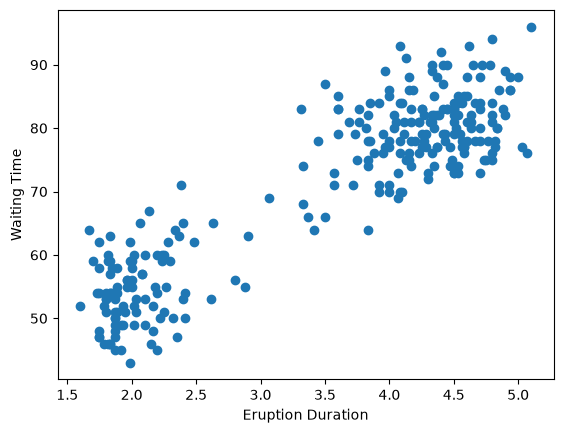

In [3]:
df = pd.read_csv("oldfaithful.csv")

plt.scatter(df["eruptions"], df["waiting"])
plt.xlabel("Eruption Duration")
plt.ylabel("Waiting Time")
plt.show()

Two clusters seem to make the most sense for this dataset because the points form two distinct groups. Using Gaussian distributions also seems reasonable because both groups have roughly elliptical shapes.

### b)

Fit a Gaussian Mixture Model (GMM) to the data. (Do not scale the data.) Recreate the scatter plot in Part a with (1) color-coding by the predicted cluster labels and (2) with the transparency (alpha) of each point set to the (normalized) probability of the cluster it is assigned to.

Is the model generally confident of its cluster predictions? Why or why not?

**Note:** You will use the fittted GMM model for the rest of this question.

**(2 points)**

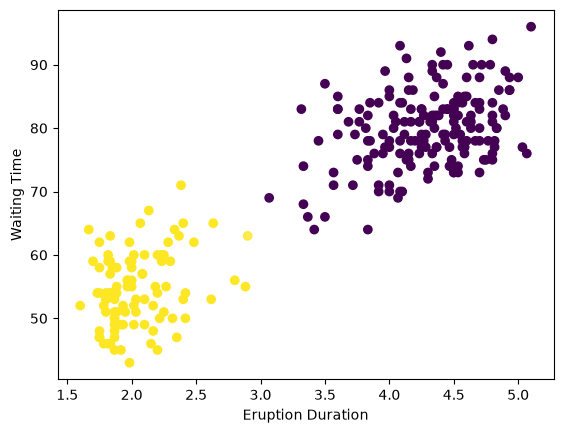

In [5]:
gmm = GaussianMixture(n_components=2, random_state=1)
gmm.fit(df)

labels = gmm.predict(df)
probs = gmm.predict_proba(df)
confidence = probs.max(axis=1)

colors = plt.cm.viridis(labels.astype(float))
colors[:, 3] = confidence

plt.scatter(df["eruptions"], df["waiting"], c=colors)
plt.xlabel("Eruption Duration")
plt.ylabel("Waiting Time")
plt.show()

The model is very confident in its predictions because most points have probabilities close to 1. The two clusters are clearly separated so there is very little uncertainty about which cluster each point belongs.

### c)

**Given the fitted model only**, what is the joint **likelihood** of a 2-minute eruption and 54-minute waiting time for the next eruption? **(2.5 points)**

In [15]:
point = np.array([[2, 54]])

likelihood = np.exp(gmm.score_samples(point))[0]
print("Joint likelihood:", likelihood)

Joint likelihood: 0.03868237287911632


### d)

**Given the fitted model only**, what is the joint **probability** of a 2-minute eruption and 54-minute waiting time for the next eruption? **(2.5 points)**

The joint probability is 0 because both variables are continuous

### e)

Define a function called `anomaly_detector`. It should take two inputs: (1) `gmm_model`, a **trained** GMM model and `X`, some observations. It should return one output: `anomalies`, which is a Boolean (logical) numpy array, which has `True` (1) for observations that are detected as an anomaly, `False` (0) otherwise. 

Note that the length of the output array should be the same as the number of observations in `X`.

The function should calculate the `gmm_model` probability for each observation in `X` occurring. The observations that are in the bottom 5% percentile in terms of model probability should then be labeled by the function as anomalies.

**(4 points)**

In [ ]:
def anomaly_detector(gmm_model, X):
    probs = np.exp(gmm_model.score_samples(X))
    threshold = np.percentile(probs, 5)
    anomalies = probs <= threshold 
    return anomalies

### f)

Using the `anomaly_detector` function, find the anomalies and print how many there are in the dataset. **(2 points)**

In [18]:
anomalies = anomaly_detector(gmm, df)

print("Number of anomalies:", anomalies.sum())

Number of anomalies: 14


### g)

What is the model probability for a 2-minute eruption and a waiting time **between 50 and 55 minutes**? (inclusive) **(3 points)**

In [21]:
def density(waiting):
    point = pd.DataFrame([[2, waiting]], columns=df.columns)
    return np.exp(gmm.score_samples(point))[0]

result, error = quad(density, 50, 55)

print("Probability:", result)

Probability: 0.17693434772507627


### h)

What is the model probability for a 2-minute eruption **(with any waiting time)**? **(3 points)**

In [23]:
result_h, error = quad(density, -np.inf, np.inf)

print("Probability:", result_h)

Probability: 0.5343231675545128


### i)

What is the model probability for a 54-minute waiting time until the next eruption, **given a 2-minute eruption time**? **(3 points)**

**Hint:** Bayes Rule



In [25]:
print("Probability:", likelihood / result_h)

Probability: 0.07239508826869248


For parts (g), (h), and (i), I used the probability densities at the exact eruption and waiting times stated in the questions. Since these variables are continuous, the probability of an exact value is zero, so the results are interpreted as densities rather than probabilities of exact observations.

### j)

`sample` a synthetic dataset of 100 observations from the model. (You are not required to use a random seed, but it is ok if you do.) Create a scatter plot of the synthetic data (no need to color code). How is it different from the original dataset in terms of the distribution of the observations? Why do you think this is the case? **(3 points)**

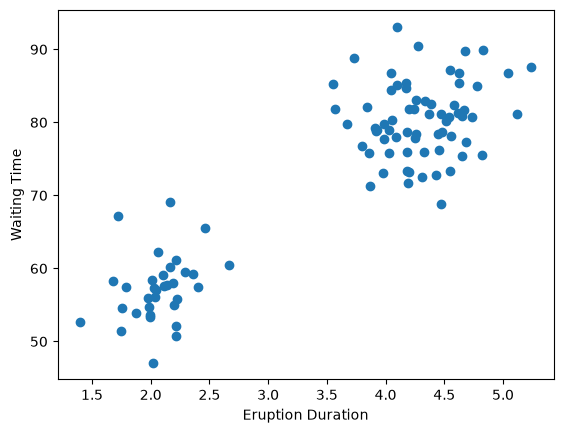

In [26]:
synthetic, labels = gmm.sample(100)

plt.scatter(synthetic[:, 0], synthetic[:, 1])
plt.xlabel("Eruption Duration")
plt.ylabel("Waiting Time")
plt.show()

The synthetic data has a similar distribution to the original data, with two main clusters. However, there are fewer points, their positions are slightly different and there are less points that could visually belong to any cluster. This is because the GMM generates new observations based on the Gaussian distributions it learned.

### k)

What is the one aspect of a GMM model that makes it fundamentally different than all of the models we have covered in STAT 362 (and STAT 301/303), regardless of a supervised or an unsupervised setting? **(2 points)**

GMM is different because it is a generative probabilistic model. It learns the probability distribution of the data allowing it to calculate likelihoods and generate new observations

## 2) Customer Personality Analysis with K-Means Clustering (13 points)

In this question, you will perform Customer Personality Analysis through clustering the customers.

Customer Personality Analysis is a detailed analysis of a company’s ideal customers. It helps a business to better understand its customers and makes it easier for them to modify products according to the specific needs, behaviors and concerns of different types of customers.

Customer Personality Analysis helps a business to modify its product based on its target customers from different types of customer segments. For example, instead of spending money to market a new product to every customer in the company’s database, a company can analyze which customer segment is most likely to buy the product and then market the product only on that particular segment.

The dataset **customer_info.csv** consists of the following information for each customer:
- `Income`: Customer's yearly household income
- `Age`: Age of customer
- `Spent`: Amount spent
- `Recency`: Number of days since customer's last purchase
- `Wines`: Amount spent on wines
- `Fruits`: Amount spent on fruits
- `Meat`: Amount spent on meat
- `Fish`: Amount spent on fish
- `Sweets`: Amount spent on sweets
- `Gold`: Amount spent on gold
- `NumDealsPurchases`: Number of deals purchased
- `NumWebPurchases`: Number of web purchases
- `NumCatalogPurchases`: Number of catalog purchases
- `NumStorePurchases`: Number of store purchases
- `NumWebVisitsMonth`: Number of web visits per month
- `Children`: Number of teenagers in customer's household
- `Family_Size`: Total members in the household

### a)

Read the data from **customer_info.csv**. Standard scale the data. **(1 point)**

In [29]:
df = pd.read_csv("customer_info.csv")

scaler = StandardScaler()
customers_scaled = scaler.fit_transform(df)

### b)

Using the scaled data and a K-Means model (`random_state=1`), find the number of clusters that makes the most sense. Try all number of clusters ($K$) values from 1 to 10 (inclusive).

You are required to use the **elbow rule** (with **inertia** as the metric) to find the optimum number of clusters. To use the elbow rule, both (1) create the elbow plot and (2) use the given function that finds the elbow in an analytic way by approximating the point of maximum curvature.

**(6 points)**

In [33]:
def get_elbow_point(inertias):

    # Coordinates of the curve
    n_points = len(inertias)
    all_coords = np.vstack((range(n_points), inertias)).T
    
    # Vector between first and last point
    first_point = all_coords[0]
    line_vec = all_coords[-1] - all_coords[0]
    line_vec_norm = line_vec / np.sqrt(np.sum(line_vec**2))
    
    # Vector from first point to all other points
    vec_from_first = all_coords - first_point
    
    # Project vectors onto the line to find the parallel component
    scalar_product = np.sum(vec_from_first * np.tile(line_vec_norm, (n_points, 1)), axis=1)
    vec_from_first_parallel = np.outer(scalar_product, line_vec_norm)
    
    # The perpendicular vector is the original vector minus the parallel component
    vec_to_line = vec_from_first - vec_from_first_parallel
    
    # The distance is the norm of the perpendicular vector
    dist_to_line = np.sqrt(np.sum(vec_to_line ** 2, axis=1))
    
    # The elbow is the point with max distance
    best_idx = np.argmax(dist_to_line)
    return best_idx + 1 

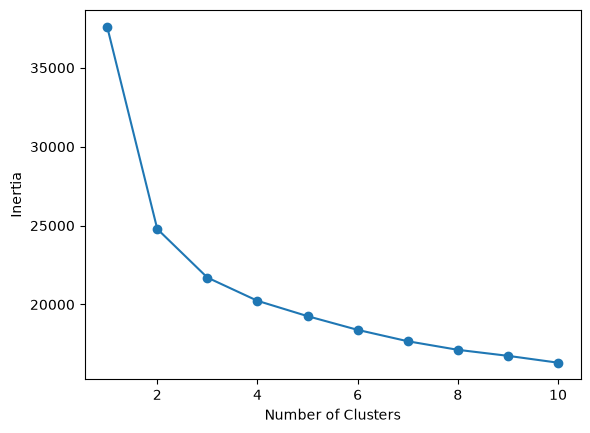

Optimal number of clusters: 3


In [34]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=1, n_init=10)
    model.fit(customers_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

best_k = get_elbow_point(inertias)
print("Optimal number of clusters:", best_k)

### c)

Using the K-Means model with the optimum number of clusters, return the cluster labels for each customer. Add the labels as a new variable to the **original** (unscaled) data.

Using the cluster labels as categories, create a boxplot of each variable grouped by cluster label. (Each variable should have as many boxplots as the number of clusters in one figure.) Note that this means a total of 17 figures (for the 17 numeric variables in the data), so consider using a grid of subplots.

**(3 points)**

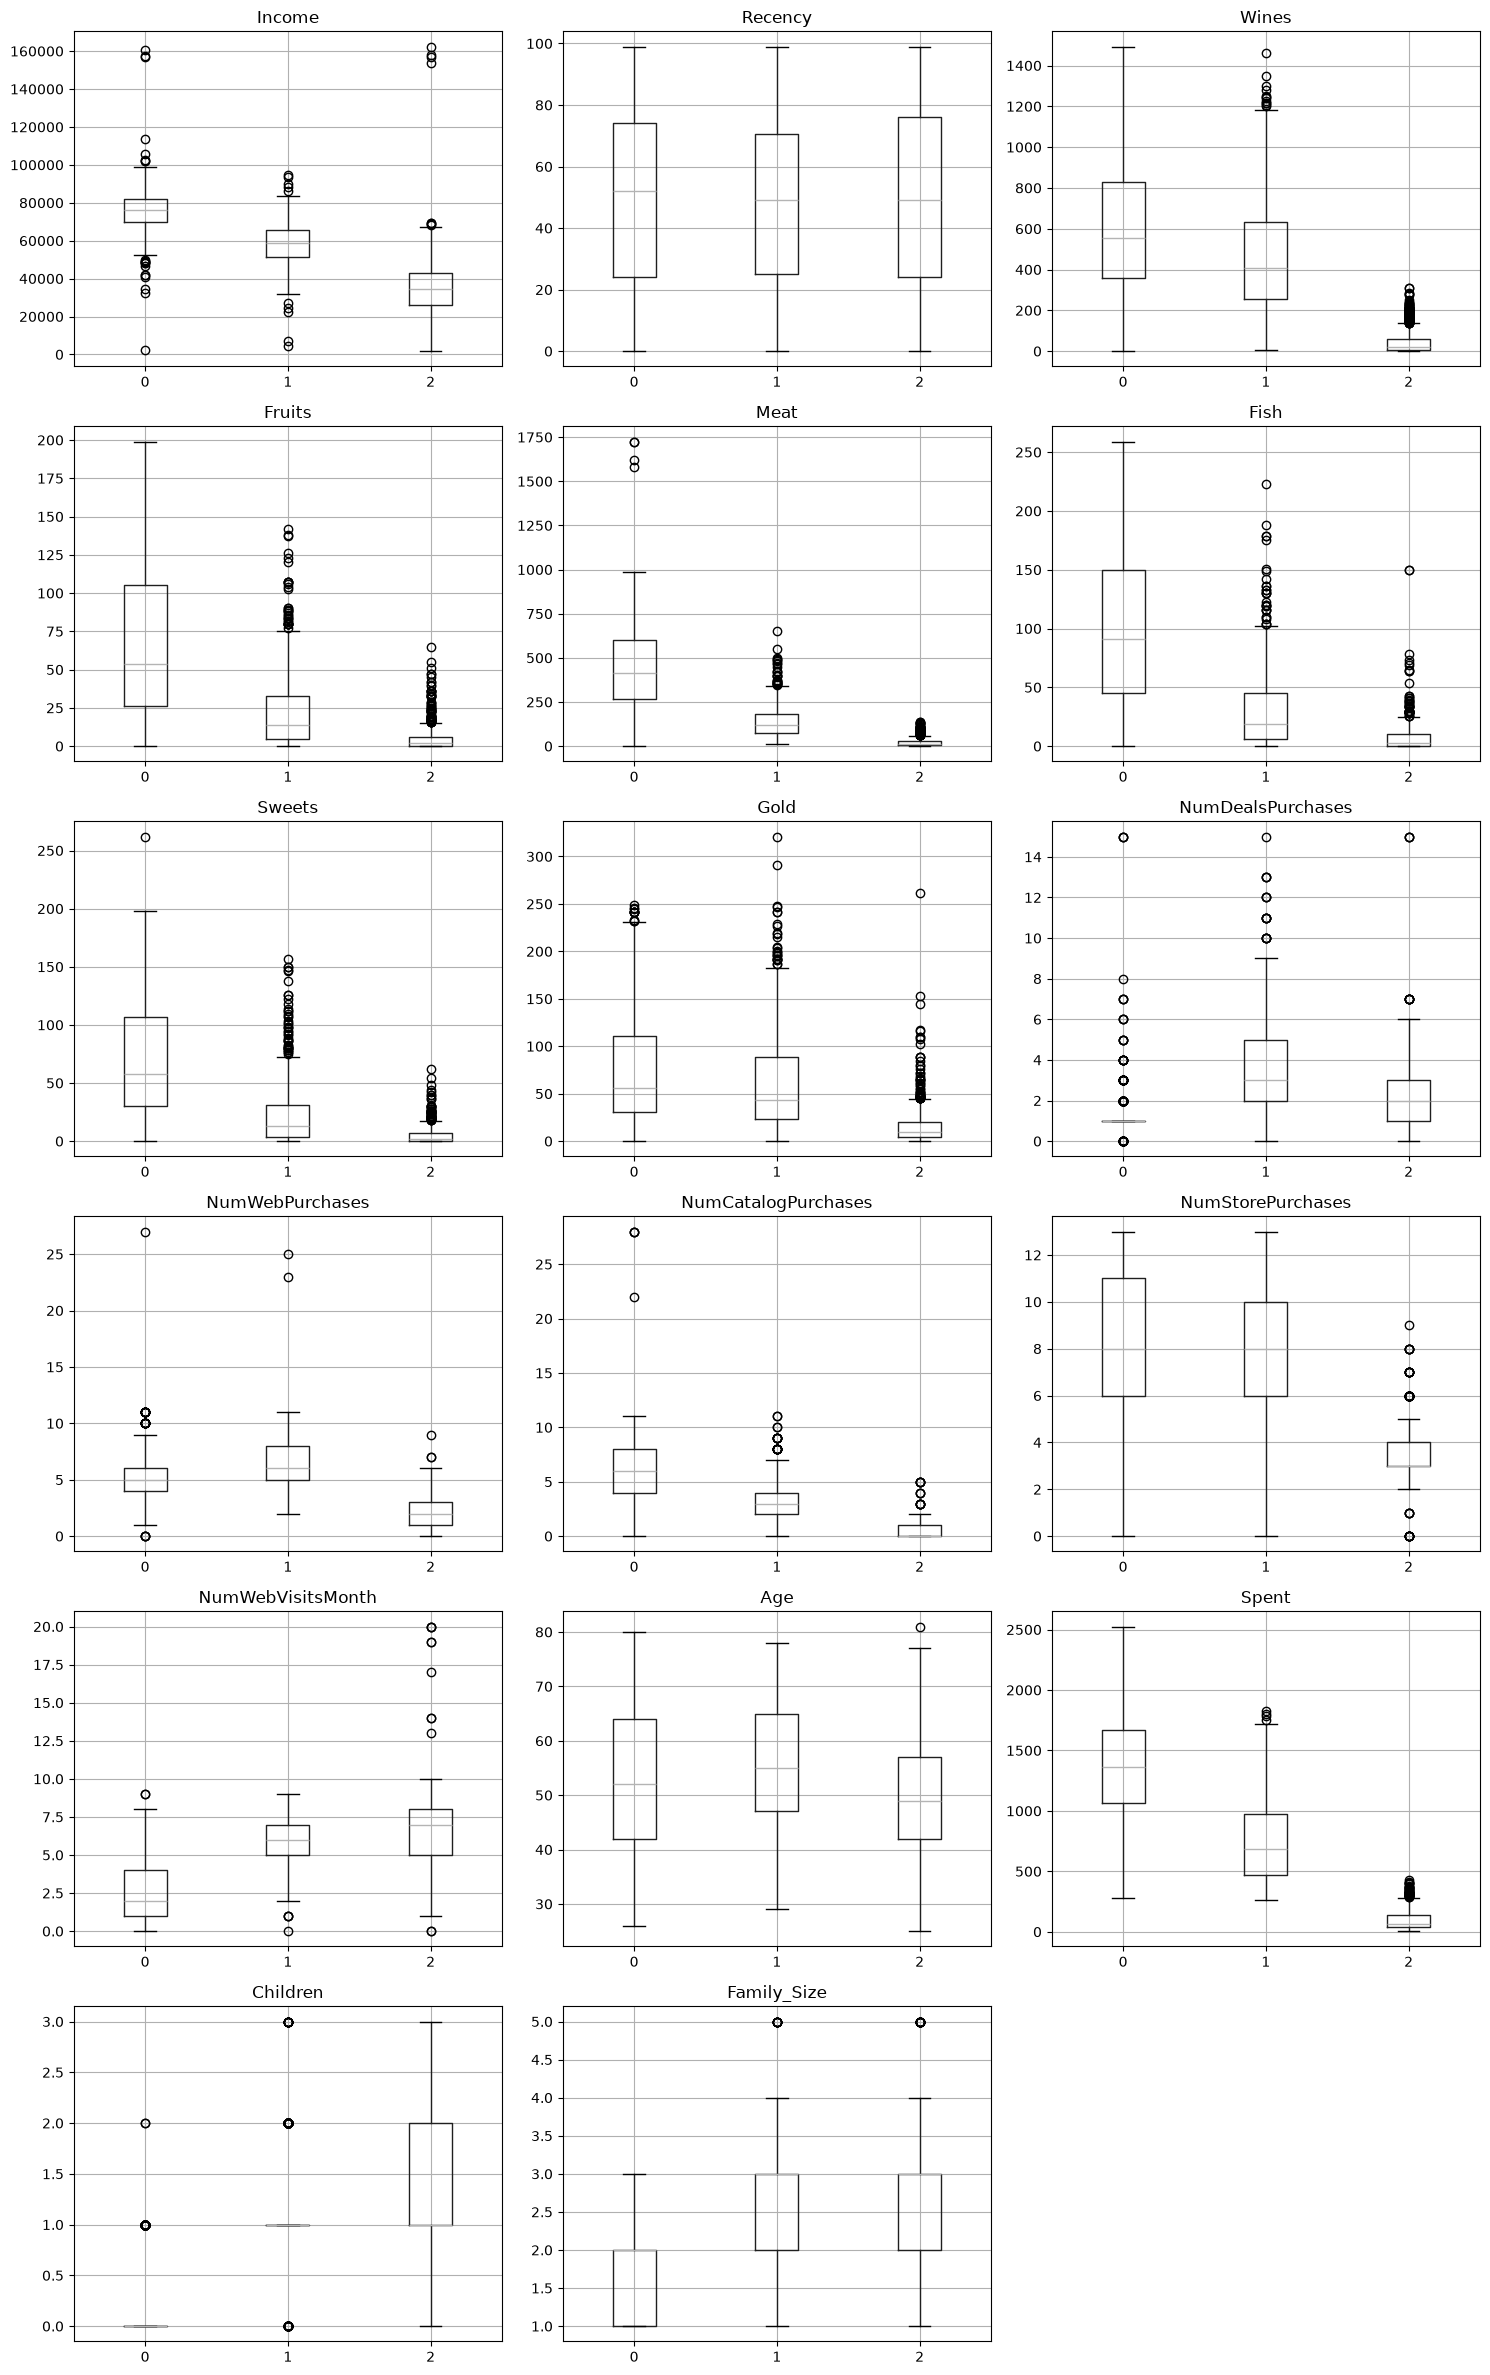

In [39]:
kmeans = KMeans(n_clusters=best_k, random_state=1, n_init=10)
labels = kmeans.fit_predict(customers_scaled)

df["Cluster"] = labels

fig, axes = plt.subplots(6, 3, figsize=(15, 24))
axes = axes.flatten()

for i, col in enumerate(df.columns[:-1]):
    df.boxplot(column=col, by="Cluster", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")

plt.suptitle("")
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

### d)

Identify and describe the clusters by how the variable values are distributed within each cluster. For each cluster, find accurate descriptions, such as "High Income", "No Children", etc. You must use at least 5 variables to accurately describe each cluster.

**(3 points)**

In [38]:
df.groupby("Cluster").mean().round(2)

,Income,Recency,Wines,Fruits,Meat,Fish,Sweets,Gold,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,Spent,Children,Family_Size
Cluster,,,,,,,,,,,,,,,,,
0,75965.43,49.75,608.99,69.09,457.17,100.71,71.26,77.26,1.33,5.19,6.06,8.40,2.83,52.72,1384.47,0.20,1.80
1,58532.10,48.30,472.45,22.94,141.14,30.72,23.35,62.47,3.76,6.48,3.12,7.82,5.76,55.57,753.06,1.16,2.83
2,35126.17,49.02,44.96,4.86,23.00,7.08,4.96,15.25,2.06,2.14,0.57,3.25,6.44,49.78,100.11,1.23,2.89


Cluster 0: High Income customers. They spend more on wine, meat, fruits, fish and sweets. They also make more catalog purchases and tend to have fewer children.

Cluster 1: Middle Income customers. They spend less than Cluster 0 but more than Cluster 2. They make more web purchases, have more children, and tend to have larger families.

Cluster 2: Lower Income customers. They spend very little on wine, meat, and other products. They also make fewer store and catalog purchases, visit the website more often, and tend to have more children.

## 3) Dimensionality Reduction and K-Means Clustering of Wikipedia Articles (15 points)

In this question, you will cluster Wikipedia articles using dimensionality reduction and a K-Means model.

### a)

Read the data from **wiki_features.csv**. Each observation is a Wikipedia article. The first column has the title of the articles and the rest of the columns (the numeric columns) represent the Term Frequency - Inverse Document Frequency (TF-IDF) features, a very commonly used Natural Language Processing (NLP) tool that expresses a text document as a numeric vector.

When a dataset that consists of a number of text documents is expressed as a numeric matrix, two things happen: (1) since each possible word in the entire dataset becomes a variable, the dimensionality becomes very high and (2) since the vast majority of possible words appear rarely or not at all in a given document, the vast majority of the values in the matrix end up being 0. A matrix with a majority of zero values is called a **sparse** matrix.

Print the `shape` and the first five rows of the data to observe what is described in the previous paragraph.

**(1 point)**

In [42]:
df = pd.read_csv("wiki_features.csv")

print(df.shape)

df.head()

(60, 13126)


,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,13115,13116,13117,13118,13119,13120,13121,13122,13123,13124
0,HTTP 404,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0
1,Alexa Internet,0.0,0.0,0.029607,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0
2,Internet Explorer,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.003772,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.011594,0.000000,0.0
3,HTTP cookie,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0
4,Google Search,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.006649,0.0


### b)

Separate the article titles and the TF-IDF features. **(1 point)**

In [44]:
titles = df.iloc[:, 0]
X = df.iloc[:, 1:]

### c)

As you should see in Part a, the dimensionality of the data is more than 200 times higher than the number of observations. In such cases, dimensionality reduction becomes not only useful but mandatory for analysis.

Since the data is sparse (as explained in Part a), the necessary calculations for a Principle Component Analysis (PCA) model will not work (properly). Therefore, you will need to use [Truncated SVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html) (Singular Value Decomposition), an extension of PCA that is developed specifically for sparse data. You can observe in the linked documentation that the usage of a Truncated SVD model object is very similar to a PCA model object.

In this question, the ultimate goal after dimensionality reduction is to cluster the articles. Therefore, along with the best number of dimensions the data will be reduced into, you will also need to find the best number of clusters. This requires optimizing both the dimensionality reduction and a clustering model, such as K-Means.

For a Truncated SVD and a K-Means model (both with `random_state=1`), find the optimum number of dimensions and the optimum number of clusters **simultaneously**. Do not scale the data. Your metric of evaluation will be [Silhouette Score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html). Note the following:

- Since the task is entirely unsupervised, there is nothing to cross-validate. You will simply use the entire dataset on the models with different combinations of input values.
- You may use nested loops or any vectorized implementation.
- Your code is required to try **at least 30 combinations** for credit.
- Your combination of models is required to have a **silhouette score of at least 0.5** for credit.

Print the optimum number of dimensions and clusters, along with the silhouette score they return.

**(10 points)**

In [46]:
best_score = -1

for d in [2, 3, 5, 10, 15, 20]:
    svd = TruncatedSVD(n_components=d, random_state=1)
    X_reduced = svd.fit_transform(X)

    for k in range(2, 8):
        kmeans = KMeans(n_clusters=k, random_state=1, n_init=10)
        labels = kmeans.fit_predict(X_reduced)

        score = silhouette_score(X_reduced, labels)

        if score > best_score:
            best_score = score
            best_dims = d
            best_k = k

print("Best dimensions:", best_dims)
print("Best clusters:", best_k)
print("Best silhouette score:", round(best_score, 4))

Best dimensions: 5
Best clusters: 7
Best silhouette score: 0.7029


### d)

Using the results of the previous part, find the optimum cluster labels for the articles. Put the labels and the article titles in a DataFrame and sort the DataFrame by the labels. Print the entire sorted DataFrame. The resulting labels should make real-life sense (entirely or for the most part).

Explain what each cluster represents (in a real-life sense). Indicate any cluster(s) and/or article(s) that seems off. You may simply write your findings or use some code to display your results and findings together in a presentable way.

**(3 points)**

In [48]:
svd = TruncatedSVD(n_components=best_dims, random_state=1)
X_reduced = svd.fit_transform(X)

kmeans = KMeans(n_clusters=best_k, random_state=1, n_init=10)
labels = kmeans.fit_predict(X_reduced)

results = pd.DataFrame({
    "Title": titles,
    "Cluster": labels
})

results = results.sort_values("Cluster")
results

,Title,Cluster
59,Adam Levine,0
57,Red Hot Chili Peppers,0
56,Skrillex,0
55,Black Sabbath,0
54,Arctic Monkeys,0
53,Stevie Nicks,0
52,The Wanted,0
51,Nate Ruess,0
50,Chad Kroeger,0
58,Sepsis,0


Cluster 0: Music  
Cluster 1: Soccer teams and organizations  
Cluster 2: Actors  
Cluster 3: Internet and websites  
Cluster 4: Climate change and policies  
Cluster 5: Soccer players  
Cluster 6: Diseases  

Most articles are grouped correctly. The 2 errors I see is that Sepsis is in the music cluster and Fever is in the internet cluster, even though both are medical topics and would fit better in Cluster 6

## 4) Principle Component Analysis (PCA) with Supervised Learning (8 points)

In this question, you will use the same dataset and general setup as **Exercise Set 9**. However, after creating the training and the test datasets, you need to (1) use a Logistic Regression model with Ridge penalty, (2) put the three necessary components of the Machine Learning (ML) workflow in a [pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) **in the correct order**, and (3) tune the pipeline with a grid search of hyperparameter values.

Take the following steps:

- Read the data from **tumor_classification.csv**. Create the response and the features. (Keep in mind that `id` is not a feature.) Create the **stratified** training and test sets with a 80%-20% split and `random_state=12`.
- Create a pipeline that preprocesses the data and feeds it to the classifier. **The pipeline must have three components in the correct order.** The classifier must have `random_state=12`.
- Tune the pipeline with a 5-fold cross-validation (CV) with `accuracy` as the scoring metric. Your grid must have at least **50 hyperparameter combinations**.
- Print the best hyperparameters of the pipeline and the average CV score they return. **The average CV accuracy must be above 97%.**
- Print the test accuracy and test confusion matrix.

In [53]:
df = pd.read_csv("tumor_classification.csv")

X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12, stratify=y)

pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA()),
                 ("model", LogisticRegression(penalty="l2", random_state=12, max_iter=2000))])

params = {
    "pca__n_components": [0.85, 0.90, 0.95, 0.97, 0.98, 0.99, 0.995, 0.999],
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid = GridSearchCV(pipe, params, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Average CV accuracy:", grid.best_score_)

y_pred = grid.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Best parameters: {'model__C': 0.1, 'pca__n_components': 0.97}
Average CV accuracy: 0.9758241758241759
Test accuracy: 0.9649122807017544
Confusion matrix:
[[72  0]
 [ 4 38]]


## 5) Math and Theory (30 points)

In this question, you will finalize the mathematical derivations/ideas behind the unsupervised ML models that have been covered in lecture. Please note the following:

- The derivations necessary for Parts a, b, and d are already performed in lecture up to a certain point. You may include the derivations in their entirety or start from where we stopped in lecture.
- To fairly assess your understanding of the math and concepts, you are required to **(1) follow the notation used in lecture and (2) add a short written explanation/justification for each step you take. Please note that these are strict requirements for any credit.**
- You can submit your derivations in any format as long as they are legible. You can include additional files in your submission if necessary.

### a)

For a GMM model and the Expectation-Maximization (EM) algorithm, complete the E-step derivation (started in lecture) for the posterior probability of the $i^{th}$ observation actually belonging to the $c^{th}$ cluster. You need to express the posterior probability in terms of the GMM model parameters ($\mu_c$, $\Sigma_c$ and $\pi_c$ for $c = 1, ..., C$).

**(7.5 points)**

![Part 5a, page 1](Part5a_page1.jpg)

![Part 5a, page 2](Part5a_page2.jpg)

![Part 5a, page 3](Part5a_page3.jpg)

### b)

For a GMM model and the EM algorithm, complete the M-step derivation (started in lecture) for the expressions that calculate the updated GMM model parameters ($\mu_c$, $\Sigma_c$ and $\pi_c$ for $c = 1, ..., C$).

You will need some identities/expressions from the [matrix cookbook](https://www.math.uwaterloo.ca/~hwolkowi/matrixcookbook.pdf).

**(10 points)**

![Part 5b, page 1](IMG_0462.jpeg)

![Part 5b, page 2](IMG_0463.jpeg)

![Part 5b, page 3](IMG_0464.jpeg)

### c)

Demonstrate how the EM algorithm becomes Lloyd's algorithm when applied to a K-Means clustering model. You must use the final output expressions for the E and M steps, as well as the assumptions for a K-Means model.

**(5 points)**

### c) EM Becomes Lloyd's Algorithm

K-Means can be seen as a special case of EM where each observation belongs to only one cluster. We assume the clusters have different means, equal weights, and the same spherical covariance matrix:

$$
\boldsymbol{\Sigma}_c = \sigma^2 \mathbf{I}, \qquad \pi_c = \frac{1}{C}
$$

**E-Step:**

From part (a), the probability that observation $i$ belongs to cluster $c$ is:

$$
\tau_c^{(i)} = \frac{\pi_c \mathcal{N}(\mathbf{x}^{(i)} \mid \boldsymbol{\mu}_c, \boldsymbol{\Sigma}_c)}{\sum_{j=1}^{C} \pi_j \mathcal{N}(\mathbf{x}^{(i)} \mid \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}
$$

Since all clusters have the same covariance and weights, the common terms cancel:

$$
\tau_c^{(i)} =
\frac{\exp\left(-\frac{\|\mathbf{x}^{(i)}-\boldsymbol{\mu}_c\|^2}{2\sigma^2}\right)}
{\sum_{j=1}^{C}\exp\left(-\frac{\|\mathbf{x}^{(i)}-\boldsymbol{\mu}_j\|^2}{2\sigma^2}\right)}
$$

As $\sigma^2$ approaches 0, the probability becomes 1 for the closest cluster and 0 for all other clusters, assuming there is a unique closest cluster.

$$
\tau_c^{(i)} =
\begin{cases}
1 & \text{if } c = \arg\min_j \|\mathbf{x}^{(i)}-\boldsymbol{\mu}_j\|^2\\
0 & \text{otherwise}
\end{cases}
$$

This is the assignment step in Lloyd's algorithm, where each observation is assigned to its nearest centroid.

**M-Step:**

From part (b), the updated mean is:

$$
\hat{\boldsymbol{\mu}}_c =
\frac{\sum_{i=1}^{M}\tau_c^{(i)}\mathbf{x}^{(i)}}{\sum_{i=1}^{M}\tau_c^{(i)}}
$$

Since the probabilities are now either 0 or 1, only observations assigned to the cluster are included in the average. Using the K-Means notation, this becomes:

$$
\mathbf{c}_j =
\frac{\sum_{i\in\text{cluster }j}\mathbf{x}^{(i)}}{\#\text{ observations in cluster }j}
$$

This is the update step in Lloyd's algorithm. The mixture weights become the proportion of observations in each cluster, and the covariance matrices stay fixed.

Therefore, when EM uses hard cluster assignments and equal spherical covariances, the E-Step becomes the nearest-centroid assignment and the M-Step becomes the centroid update. These are the two steps of Lloyd's algorithm.

---

AI disclosure: I sent this prompt to ChatGPT to generate the format of the solution:

"I have my solution for question 5c of my STAT 362 homework, but I need to put it in my Jupyter notebook using Markdown and LaTex. Can you convert everything below into Markdown format so the equations render correctly in Quarto? Please dont change the math or the explanations, just format it properly.

5c) EM Becomes Lloyd's Algorithm

K-Means is a special case of EM where each observation is assigned to one cluster. We assume the clusters have different means, equal mixture weights pi_c = 1/C, and the same spherical covariance Sigma_c = sigma²I.

E-step:

From part a, the posterior probability is:

tau_c^(i) = [pi_c N(x^(i) | mu_c, Sigma_c)] / [sum from j=1 to C of pi_j N(x^(i) | mu_j, Sigma_j)]

Since Sigma_c = sigma²I and all weights are equal, the common terms cancel. This gives:

tau_c^(i) = exp(-||x^(i) - mu_c||² / 2sigma²) / [sum from j=1 to C exp(-||x^(i) - mu_j||² / 2sigma²)]

As sigma² approaches zero, the closest cluster gets probability 1 and all other clusters get 0, assuming there is one unique closest cluster.

tau_c^(i) = 1 if c = argmin_j ||x^(i) - mu_j||², and 0 otherwise.

This is the assignment step of Lloyd's algorithm because every observation goes to its closest centroid.

M-step:

From part b, the updated mean is:

mu_hat_c = [sum from i=1 to M of tau_c^(i) x^(i)] / [sum from i=1 to M of tau_c^(i)]

Since tau is now either 0 or 1, only observations belonging to that cluster are used to calculate the mean.

Using the K-Means notation:

c_j = [sum of x^(i) for i in cluster j] / [number of observations in cluster j]

This is Lloyd's update step because the centroid is the average of the observations assigned to that cluster. The mixture weights become the proportion of observations in each cluster, and the covariance matrices remain fixed.

Therefore, the E-step of EM becomes the nearest centroid assignment and the M-step becomes the centroid update. Alternating these two steps gives Lloyd's algorithm.

Please just format all of this into a Jupyter Markdown cell with proper LaTex equations, keeping my notation and explanations. Dont add extra steps or make it more complicated."

### d)

Complete the derivation (started in the lecture) that shows how the eigenvectors of the covariance matrix of a dataset return its principle components (PCs) and the eigenvalues of the covariance matrix return the amount of variance each PC holds.

Lastly, explain why the equation makes intuitive sense by comparing the definition of the PCs and the mathematical definition of eigenvalues/eigenvectors.

**(7.5 points)**

![Part 5d, page 1](IMG_0465.jpeg)

![Part 5d, page 2](IMG_0466.jpeg)

Principal components are orthogonal directions that capture the most variance in the data. Eigenvectors are directions that a matrix scales without changing their direction, while eigenvalues describe how much they are scaled. Since the covariance matrix represents variation in the data, its eigenvectors identify the main directions of variation. The eigenvector with the largest eigenvalue captures the most variance, which is why it becomes the first principal component.